In [2]:
#first we will import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
#loading the data into dataframe
df = pd.read_csv(r'C:\Users\dgajj\OneDrive\Desktop\intern\Zomato-analytics-project\data\zomato.csv')
df.tail()


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
51712,https://www.zomato.com/bangalore/best-brews-fo...,"Four Points by Sheraton Bengaluru, 43/3, White...",Best Brews - Four Points by Sheraton Bengaluru...,No,No,3.6 /5,27,080 40301477,Whitefield,Bar,NaN,Continental,"1,500","[('Rated 5.0', ""RATED\n Food and service are ...",[],Pubs and bars,Whitefield
51713,https://www.zomato.com/bangalore/vinod-bar-and...,"Number 10, Garudachar Palya, Mahadevapura, Whi...",Vinod Bar And Restaurant,No,No,NaN,0,+91 8197675843,Whitefield,Bar,NaN,Finger Food,600,[],[],Pubs and bars,Whitefield
51714,https://www.zomato.com/bangalore/plunge-sherat...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Plunge - Sheraton Grand Bengaluru Whitefield H...,No,No,NaN,0,NaN,Whitefield,Bar,NaN,Finger Food,"2,000",[],[],Pubs and bars,Whitefield
51715,https://www.zomato.com/bangalore/chime-sherato...,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Chime - Sheraton Grand Bengaluru Whitefield Ho...,No,Yes,4.3 /5,236,080 49652769,"ITPL Main Road, Whitefield",Bar,"Cocktails, Pizza, Buttermilk",Finger Food,"2,500","[('Rated 4.0', 'RATED\n Nice and friendly pla...",[],Pubs and bars,Whitefield
51716,https://www.zomato.com/bangalore/the-nest-the-...,"ITPL Main Road, KIADB Export Promotion Industr...",The Nest - The Den Bengaluru,No,No,3.4 /5,13,+91 8071117272,"ITPL Main Road, Whitefield","Bar, Casual Dining",NaN,"Finger Food, North Indian, Continental","1,500","[('Rated 5.0', 'RATED\n Great ambience , look...",[],Pubs and bars,Whitefield


In [4]:
#chekking the datas size and shape ,infp
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   url                          51717 non-null  object
 1   address                      51717 non-null  object
 2   name                         51717 non-null  object
 3   online_order                 51717 non-null  object
 4   book_table                   51717 non-null  object
 5   rate                         43942 non-null  object
 6   votes                        51717 non-null  int64 
 7   phone                        50509 non-null  object
 8   location                     51696 non-null  object
 9   rest_type                    51490 non-null  object
 10  dish_liked                   23639 non-null  object
 11  cuisines                     51672 non-null  object
 12  approx_cost(for two people)  51371 non-null  object
 13  reviews_list                 51

In [5]:
df.isnull().count()

url                            51717
address                        51717
name                           51717
online_order                   51717
book_table                     51717
rate                           51717
votes                          51717
phone                          51717
location                       51717
rest_type                      51717
dish_liked                     51717
cuisines                       51717
approx_cost(for two people)    51717
reviews_list                   51717
menu_item                      51717
listed_in(type)                51717
listed_in(city)                51717
dtype: int64

In [6]:
#filtering only columns that we need only
core_columns = ['name','location','cuisines','rate','votes','approx_cost(for two people)']
df = df[core_columns]
df.head()
df.shape
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   name                         51717 non-null  object
 1   location                     51696 non-null  object
 2   cuisines                     51672 non-null  object
 3   rate                         43942 non-null  object
 4   votes                        51717 non-null  int64 
 5   approx_cost(for two people)  51371 non-null  object
dtypes: int64(1), object(5)
memory usage: 2.4+ MB


In [7]:
#cleaning the columns that are not needed 
df['cost_for_two'] = df['approx_cost(for two people)']
df = df.drop(columns=['approx_cost(for two people)'])
df.head()

,name,location,cuisines,rate,votes,cost_for_two
0,Jalsa,Banashankari,"North Indian, Mughlai, Chinese",4.1/5,775,800
1,Spice Elephant,Banashankari,"Chinese, North Indian, Thai",4.1/5,787,800
2,San Churro Cafe,Banashankari,"Cafe, Mexican, Italian",3.8/5,918,800
3,Addhuri Udupi Bhojana,Banashankari,"South Indian, North Indian",3.7/5,88,300
4,Grand Village,Basavanagudi,"North Indian, Rajasthani",3.8/5,166,600


In [8]:
#replacing the new and - value with np.nan
df['rate'] = df['rate'].replace(['NEW','-'],np.nan)

#extercting only number before the '/' in rating
df['rate'] = pd.to_numeric(df['rate'].str.split('/').str[0],errors='coerce')



In [9]:
#removing the , in cost_for_two column
df['cost_for_two'] = df['cost_for_two'].astype(str).str.replace(',','')

#converting the coloumns values into numbers and coerce means if there is any error turn that into nan
df['cost_for_two'] = pd.to_numeric(df['cost_for_two'],errors='coerce')

In [10]:
#caling the rows where the this two columns have nan vaue
df = df.dropna(subset=['cost_for_two','rate','cuisines'])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41410 entries, 0 to 51716
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          41410 non-null  object 
 1   location      41410 non-null  object 
 2   cuisines      41410 non-null  object 
 3   rate          41410 non-null  float64
 4   votes         41410 non-null  int64  
 5   cost_for_two  41410 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 2.2+ MB


In [11]:
#removing the duplicate 
df.shape
#filtred values so that each restaurnt apper only each time 
df = df.drop_duplicates(subset=['name','location'])
df.shape

#
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 9216 entries, 0 to 51677
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          9216 non-null   object 
 1   location      9216 non-null   object 
 2   cuisines      9216 non-null   object 
 3   rate          9216 non-null   float64
 4   votes         9216 non-null   int64  
 5   cost_for_two  9216 non-null   float64
dtypes: float64(2), int64(1), object(3)
memory usage: 504.0+ KB


name            0
location        0
cuisines        0
rate            0
votes           0
cost_for_two    0
dtype: int64

In [12]:
#creating new column true_score that star rating with public credibility because we should give score based on which restaurent has score that matter rather then with on or two rating 
conditions = [df['votes'] >= 2000, df['votes'] >= 500 ]

values = [0.5,0.2]

bouns = np.select(conditions,values,default=0.0)

df['true_score'] = df['rate'] + bouns

df.sort_values(by='true_score',ascending=False)[['name','location','rate','votes','cost_for_two','true_score']].head(10)

,name,location,rate,votes,cost_for_two,true_score
18496,Milano Ice Cream,Indiranagar,4.9,2090,400.0,5.4
6746,Flechazo,Whitefield,4.9,2745,1400.0,5.4
3921,Byg Brewski Brewing Company,Sarjapur Road,4.9,16345,1600.0,5.4
8260,AB's - Absolute Barbecues,BTM,4.9,6375,1600.0,5.4
8275,Asia Kitchen By Mainland China,Koramangala 5th Block,4.9,2178,1500.0,5.4
9935,House Of Commons,Koramangala 5th Block,4.8,4390,1000.0,5.3
39546,Chili's American Grill & Bar,Malleshwaram,4.8,6433,1400.0,5.3
40507,The Globe Grub,Marathahalli,4.8,3932,1300.0,5.3
40506,AB's - Absolute Barbecues,Marathahalli,4.8,12121,1600.0,5.3
3338,Brahmin's Coffee Bar,Basavanagudi,4.8,2679,100.0,5.3


Text(0.5, 1.0, 'comparing cost to the ratings')

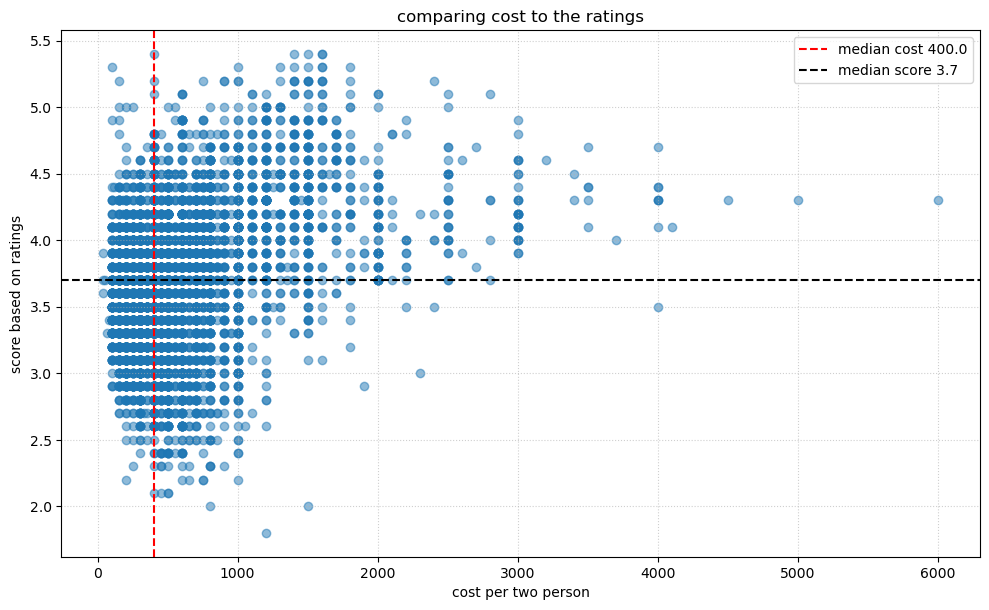

In [13]:
#chart 1 for cheaking if the higer prices guarantees a better food

plt.figure(figsize=(10,6))
plt.scatter(df['cost_for_two'],df['true_score'],alpha=0.5)
median_cost = df['cost_for_two'].median()
median_score = df['true_score'].median()
plt.axvline(median_cost,color='red', linestyle='--', linewidth=1.5,label=f'median cost {median_cost}')
plt.axhline(median_score,color='black', linestyle='--', linewidth=1.5,label=f'median score {median_score}')
plt.xlabel('cost per two person')
plt.ylabel('score based on ratings')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.legend()
plt.title('comparing cost to the ratings')


#key take away from this Dense Cluster (Bottom-Left & Top-Left): The overwhelming majority of Bangalore's food market operates under ₹1,000.   High-Cost Outliers (Right Side): Venues charging over ₹2,500 rarely drop below a 3.5 rating. While higher spend does not strictly guarantee top-tier status (5.0+), it acts as a quality floor where very few expensive restaurants suffer low ratings.   Value Champions (Top-Left): Venues with scores above 4.5 but costs under ₹500 represent the highest-value dining options in the city.   

In [14]:
#finding the restaurant with chper then median cost and higer then median score
best_restaurant = ((df['cost_for_two'] <= 400)  & (df['true_score'] >= 4.5)) 
df_filteredof = df[best_restaurant]
df_filteredof.sort_values(by='true_score',ascending=False)


,name,location,cuisines,rate,votes,cost_for_two,true_score
18496,Milano Ice Cream,Indiranagar,"Ice Cream, Desserts",4.9,2090,400.0,5.4
3338,Brahmin's Coffee Bar,Basavanagudi,South Indian,4.8,2679,100.0,5.3
17672,Corner House Ice Cream,Indiranagar,"Ice Cream, Desserts",4.7,2139,400.0,5.2
39518,CTR,Malleshwaram,South Indian,4.7,4408,150.0,5.2
5153,Belgian Waffle Factory,Brigade Road,Desserts,4.9,1746,400.0,5.1
...,...,...,...,...,...,...,...
9834,Khawa Karpo,Koramangala 5th Block,"Chinese, Tibetan, Momos",4.3,988,350.0,4.5
39445,Aubree,Sadashiv Nagar,"Cafe, Bakery",4.3,722,400.0,4.5
40313,HVR Veg,Seshadripuram,South Indian,4.5,96,300.0,4.5
40336,Hotel Nalapaka,Rajajinagar,South Indian,4.3,678,400.0,4.5


Text(0.5, 1.0, 'number of restaurants in each area')

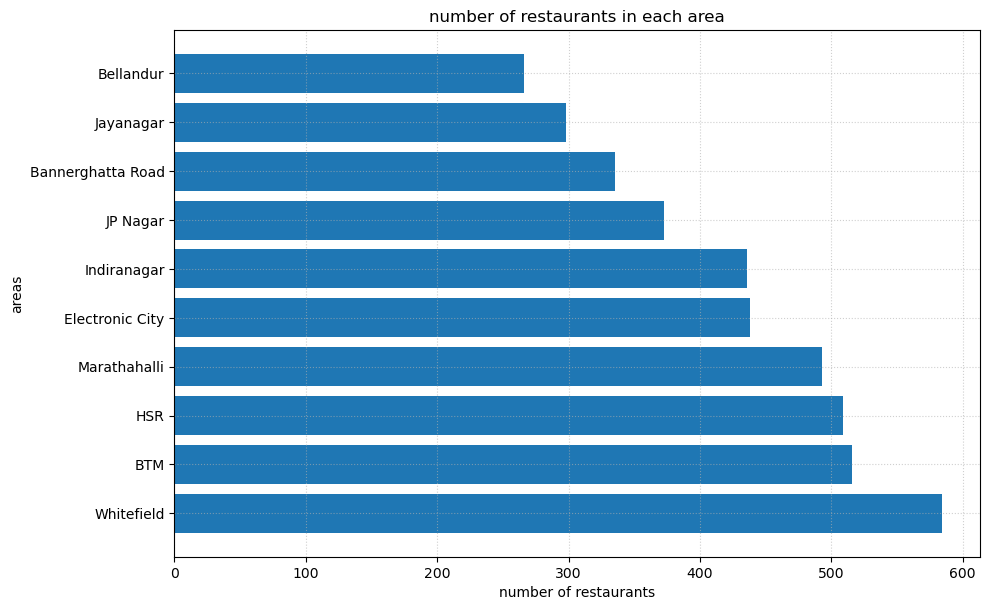

In [15]:
#Neighborhood Analysis (Bar Chart) for finding the highest resatutrant avialable in areas in bangalore 

df_data = df['location'].value_counts().head(10)
# print(df_data)


plt.figure(figsize=(10,6))
plt.barh(df_data.index,df_data.values)
plt.xlabel('number of restaurants')
plt.ylabel('areas')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.title('number of restaurants in each area')




In [16]:
locations = df.groupby('location').agg({
    'true_score': 'mean' , #
    'name' : 'count'
}).reset_index()
popular_locations = locations[locations['name'] >= 50]
top_locations = popular_locations.sort_values(by='true_score',ascending=False)
top_locations.head(10)
new_df = top_locations.head(10)
print(locations)

             location  true_score  name
0                 BTM    3.568023   516
1        Banashankari    3.654338   219
2           Banaswadi    3.489286   140
3   Bannerghatta Road    3.490746   335
4        Basavanagudi    3.691954   174
..                ...         ...   ...
87     West Bangalore    3.500000     2
88         Whitefield    3.628596   584
89      Wilson Garden    3.453125    32
90          Yelahanka    3.700000     2
91        Yeshwantpur    3.490625    64

[92 rows x 3 columns]


Text(0.5, 1.0, 'number of good restaurants in each area')

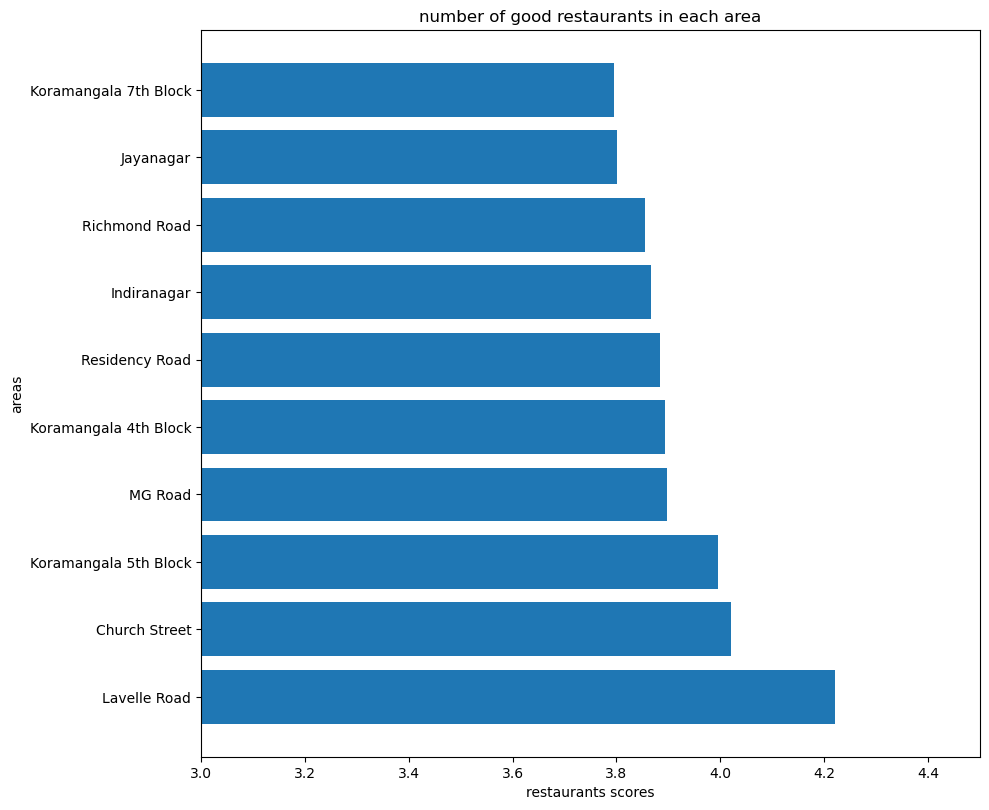

In [17]:
#ploting the chart that shows area with higest rated restaurant
plt.figure(figsize=(10,8))
plt.barh(new_df.location,new_df.true_score)
plt.xlim(3.0, 4.5)
plt.xlabel('restaurants scores')
plt.ylabel('areas')
plt.tight_layout()
plt.title('number of good restaurants in each area')

In [18]:
#
df

,name,location,cuisines,rate,votes,cost_for_two,true_score
0,Jalsa,Banashankari,"North Indian, Mughlai, Chinese",4.1,775,800.0,4.3
1,Spice Elephant,Banashankari,"Chinese, North Indian, Thai",4.1,787,800.0,4.3
2,San Churro Cafe,Banashankari,"Cafe, Mexican, Italian",3.8,918,800.0,4.0
3,Addhuri Udupi Bhojana,Banashankari,"South Indian, North Indian",3.7,88,300.0,3.7
4,Grand Village,Basavanagudi,"North Indian, Rajasthani",3.8,166,600.0,3.8
...,...,...,...,...,...,...,...
51611,Chung Wah,"ITPL Main Road, Whitefield","Chinese, Momos",2.5,73,800.0,2.5
51614,Nawabs Empire,"ITPL Main Road, Whitefield","North Indian, Chinese, Arabian, Momos",3.2,5,300.0,3.2
51620,Fujian Express,"ITPL Main Road, Whitefield","Thai, Chinese, Momos",3.8,182,600.0,3.8
51632,SeeYa Restaurant,KR Puram,"North Indian, Kerala, Chinese",3.3,4,350.0,3.3


In [21]:
#in top locations which of the cuisines are more popular 
#first we have to remove the data from , and converte it into list

df = df.assign(cuisine=df['cuisines'].str.split(', ')).explode('cuisine')
top = top_locations.head(8)
list_top_loc = top['location'].tolist()




commom_cuisine = df['cuisine'].value_counts().head(6).index
top_loc_cui = df[(df['cuisine'].isin(commom_cuisine)) & (df['location'].isin(list_top_loc))]
top_loc_cui
# commom_cuisine

['Lavelle Road', 'Church Street', 'Koramangala 5th Block', 'MG Road', 'Koramangala 4th Block', 'Residency Road', 'Indiranagar', 'Richmond Road']


,name,location,cuisines,rate,votes,cost_for_two,true_score,cuisine
2542,eat.fit,Koramangala 5th Block,"Healthy Food, North Indian, Biryani, Continent...",4.6,143,500.0,4.6,North Indian
2542,eat.fit,Koramangala 5th Block,"Healthy Food, North Indian, Biryani, Continent...",4.6,143,500.0,4.6,Biryani
2542,eat.fit,Koramangala 5th Block,"Healthy Food, North Indian, Biryani, Continent...",4.6,143,500.0,4.6,Continental
2542,eat.fit,Koramangala 5th Block,"Healthy Food, North Indian, Biryani, Continent...",4.6,143,500.0,4.6,North Indian
2542,eat.fit,Koramangala 5th Block,"Healthy Food, North Indian, Biryani, Continent...",4.6,143,500.0,4.6,Biryani
...,...,...,...,...,...,...,...,...
48144,RS Shiv Sagar Express,Residency Road,"South Indian, North Indian, Chinese, Fast Food",4.0,67,300.0,4.0,Fast Food
48144,RS Shiv Sagar Express,Residency Road,"South Indian, North Indian, Chinese, Fast Food",4.0,67,300.0,4.0,South Indian
48144,RS Shiv Sagar Express,Residency Road,"South Indian, North Indian, Chinese, Fast Food",4.0,67,300.0,4.0,North Indian
48144,RS Shiv Sagar Express,Residency Road,"South Indian, North Indian, Chinese, Fast Food",4.0,67,300.0,4.0,Chinese


In [22]:
#heat map matrix
# pivot_table = top_loc_cui.pivot_table(
#     index='location',
#     columns='cuisine',
#     values='true_score',
#     aggfunc='mean'
# )
# pivot_table

cuisine,Biryani,Chinese,Continental,Fast Food,North Indian,South Indian
location,,,,,,
Church Street,3.949333,3.979817,4.258421,3.588571,3.917544,3.974766
Indiranagar,3.912827,3.852372,4.163608,3.730893,3.896854,3.741055
Koramangala 4th Block,3.958974,4.065976,4.205882,3.394545,4.052000,3.750000
Koramangala 5th Block,3.911144,4.219561,4.483803,3.832588,4.188326,3.730151
Lavelle Road,NaN,4.037736,4.061538,3.333333,4.036290,4.008000
MG Road,3.568000,3.883099,4.298697,3.712048,3.844713,3.837838
Residency Road,3.927660,3.981604,4.161165,3.861818,4.059167,3.899187
Richmond Road,3.893694,3.832456,3.976448,3.669231,3.772727,3.541667


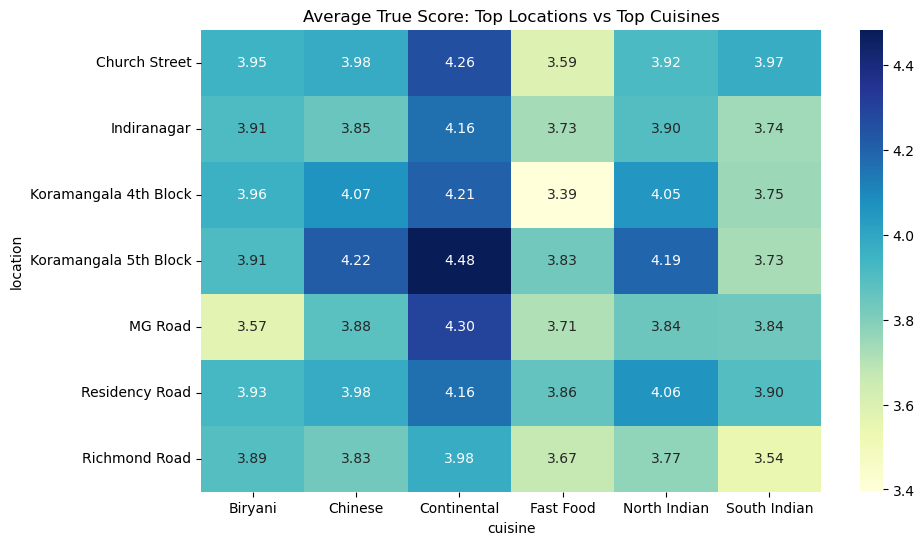

In [29]:
pivot_table = top_loc_cui.pivot_table(
    index='location',
    columns='cuisine',
    values='true_score',
    aggfunc='mean'
)
pivot_table =pivot_table.dropna()
plt.figure(figsize=(10,6))
import seaborn as sns
sns.heatmap(pivot_table, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title("Average True Score: Top Locations vs Top Cuisines")
plt.show()

C:\Users\dgajj\AppData\Local\Temp\ipykernel_32952\437759209.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(


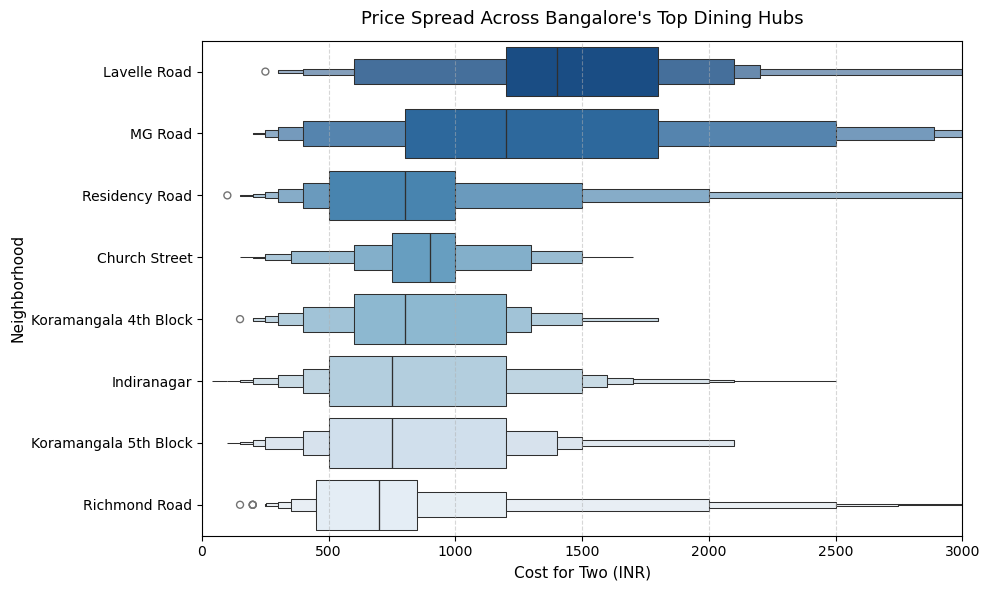

In [34]:
df_top_neighborhoods = df[df['location'].isin(list_top_loc)].copy()
group_order_costs = (
    df_top_neighborhoods.groupby('location')['cost_for_two'].mean().sort_values(ascending=False).index)


plt.figure(figsize=(10,6))
sns.boxenplot(
    data=df_top_neighborhoods,
    x='cost_for_two',
    y='location',
    order=group_order_costs,
    palette='Blues_r'
)

plt.title("Price Spread Across Bangalore's Top Dining Hubs", fontsize=13, pad=12)
plt.xlabel("Cost for Two (INR)", fontsize=11)
plt.ylabel("Neighborhood", fontsize=11)
plt.xlim(0, 3000)
plt.grid(True, linestyle='--', alpha=0.5, axis='x')
plt.tight_layout()
plt.savefig('neighborhood_cost_boxplot.png', dpi=300)
plt.show()

C:\Users\dgajj\AppData\Local\Temp\ipykernel_32952\2457199432.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Text(0.5, 1.0, '2. Correlation Matrix of Numeric Metrics')

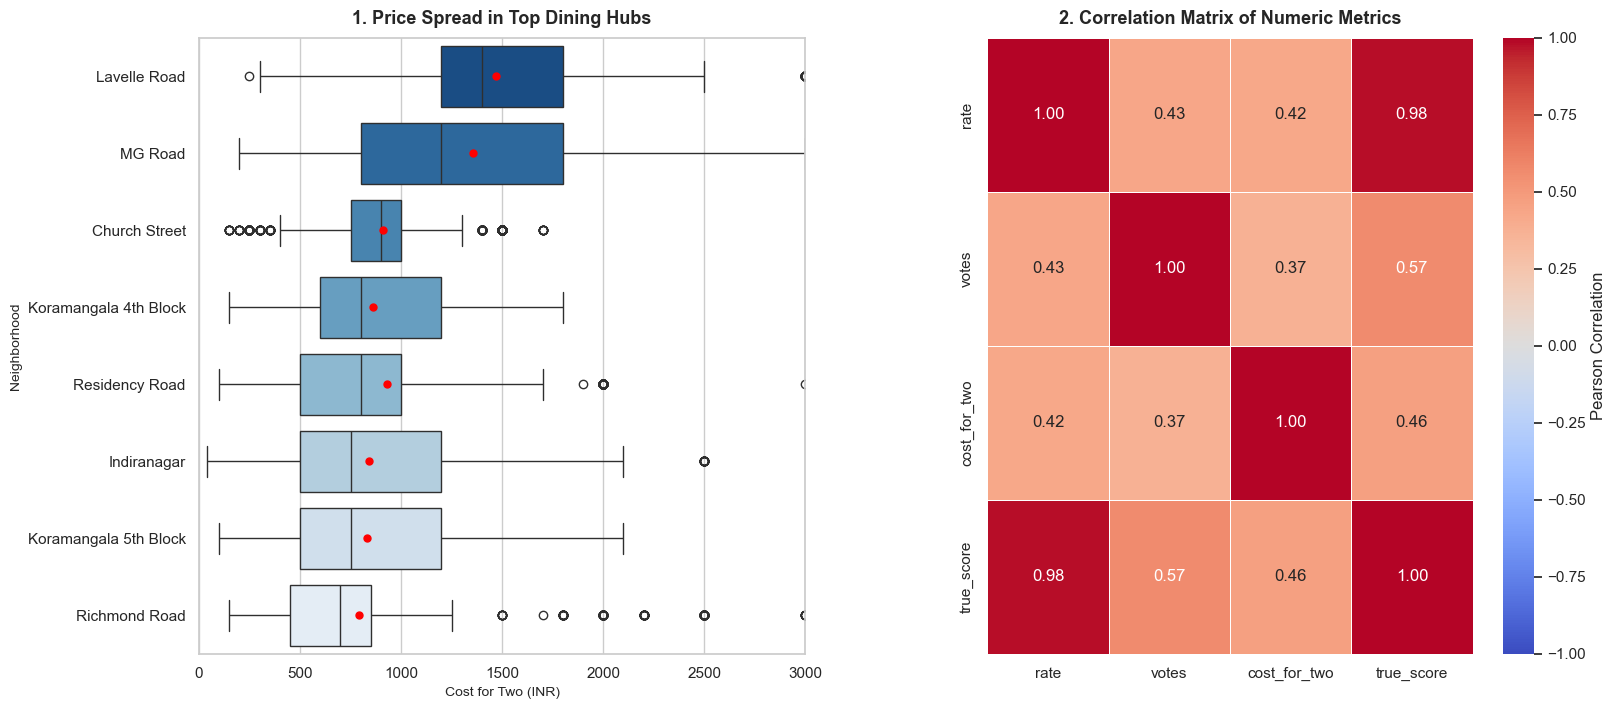

In [41]:
sns.set_theme(style='whitegrid')
fig,axes = plt.subplots(1, 2, figsize=(18, 8))
plt.subplots_adjust(wspace=0.3)

#SUBPLOT 1: Cost Distribution Across Top Hubs (Box Plot)
df_top_hubs = df[df['location'].isin(list_top_loc)].copy()
order_by_cost = (
    df_top_hubs.groupby('location')['cost_for_two']
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    ax=axes[0],
    data=df_top_hubs,
    x='cost_for_two',
    y='location',
    order=order_by_cost,
    palette='Blues_r',
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": "5"}
)

axes[0].set_title("1. Price Spread in Top Dining Hubs", fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel("Cost for Two (INR)", fontsize=10)
axes[0].set_ylabel("Neighborhood", fontsize=10)
axes[0].set_xlim(0, 3000)

#SUBPLOT 2: Feature Correlation Matrix
numeric_cols = ['rate', 'votes', 'cost_for_two', 'true_score']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(
    corr_matrix,
    ax=axes[1],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation'}
)
axes[1].set_title("2. Correlation Matrix of Numeric Metrics", fontsize=13, fontweight='bold', pad=10)
